Load the images and turn them to grayscale

In [1]:
from helpers import load_images, to_grayscale

# Load images from your directory
images = load_images("images")
grayscale = {name: to_grayscale(image) for name, image in images.items()}

Let's define the gaussian derivative kernels and take a look at them. I bypass the need for 2 different convolutions by using the fact that: 

$$ \frac{d}{dx} (f(x) \star g(x)) = f(x) \star \frac{d}{dx} g(x) $$

this way I obtain a gaussian derivative kernel directly, by just plugging numbers in.
Standard deviation are, by default, a sixth of the kernel size. 

In [2]:
from kernels import gaussian_derivative_kernels

gaussian_filters = {
    3: gaussian_derivative_kernels(radius=1),
    7: gaussian_derivative_kernels(radius=3),
    15: gaussian_derivative_kernels(radius=7),
    31: gaussian_derivative_kernels(radius=15),
}

Below is a visualisation of the 2 kernels with size 7x7.

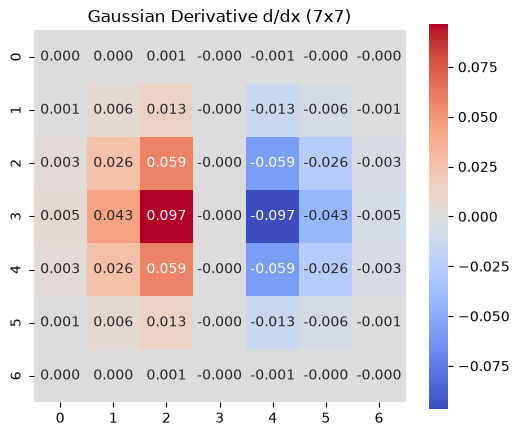

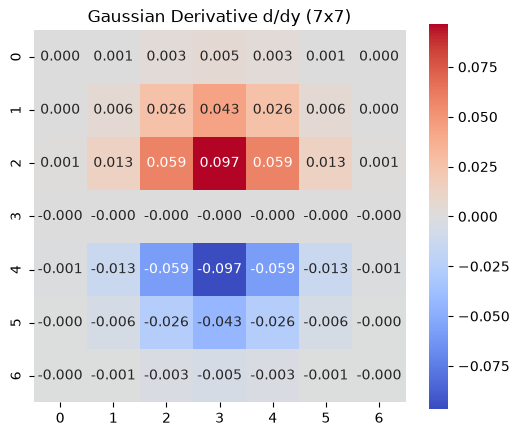

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

Gx, Gy = gaussian_filters[7]

plt.figure(figsize=(6, 5))
sns.heatmap(Gx, annot=True, fmt=".3f", cmap="coolwarm", center=0, square=True)
plt.title("Gaussian Derivative d/dx (7x7)")
plt.show()
plt.figure(figsize=(6, 5))
sns.heatmap(Gy, annot=True, fmt=".3f", cmap="coolwarm", center=0, square=True)
plt.title("Gaussian Derivative d/dy (7x7)")
plt.show()

In [4]:
import numpy as np
from scipy.signal import convolve2d

edges_3 = {
    name: np.hypot(
        convolve2d(img, gaussian_filters[3][0], mode="same"),
        convolve2d(img, gaussian_filters[3][1], mode="same")
    )
    for name, img in grayscale.items()
}

edges_7 = {
    name: np.hypot(
        convolve2d(img, gaussian_filters[7][0], mode="same"),
        convolve2d(img, gaussian_filters[7][1], mode="same")
    )
    for name, img in grayscale.items()
}

edges_15 = {
    name: np.hypot(
        convolve2d(img, gaussian_filters[15][0], mode="same"),
        convolve2d(img, gaussian_filters[15][1], mode="same")
    )
    for name, img in grayscale.items()
}

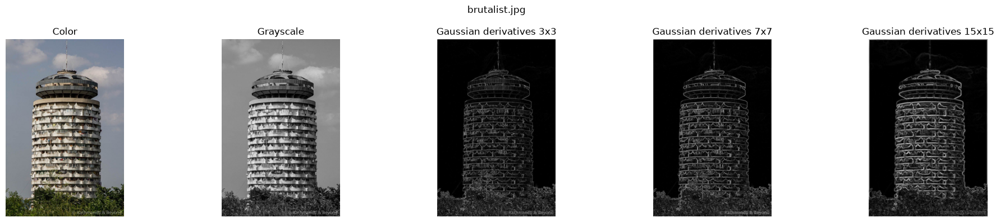

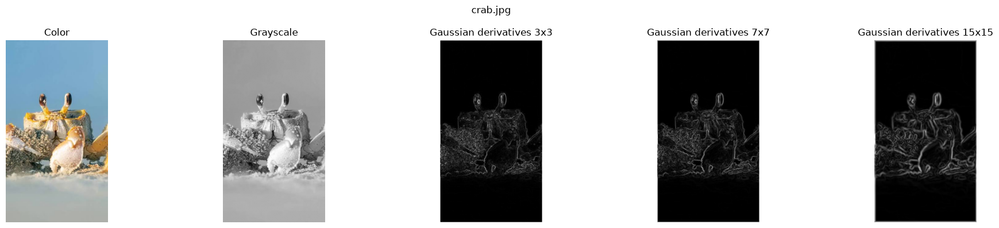

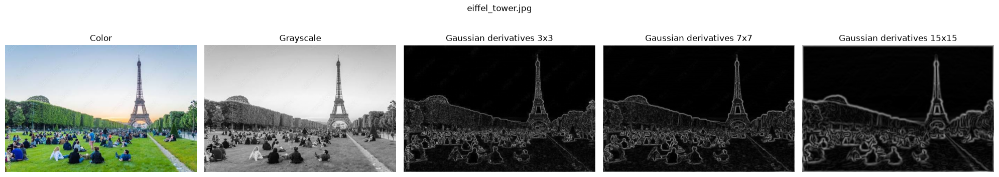

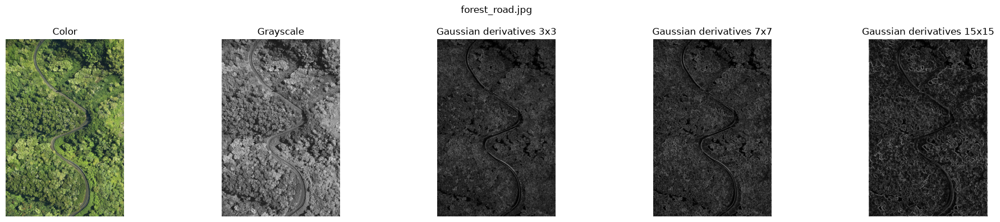

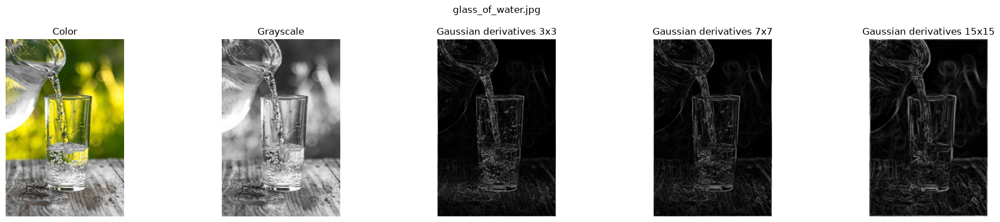

...

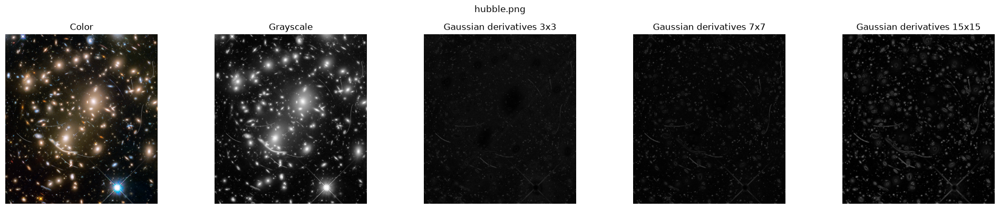

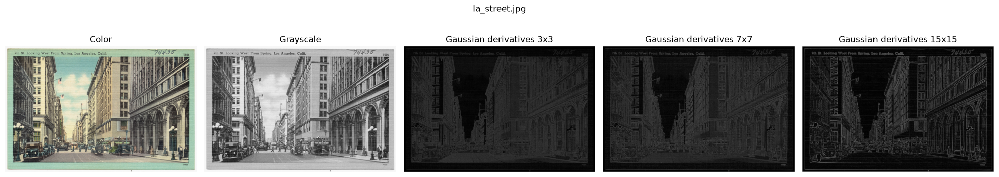

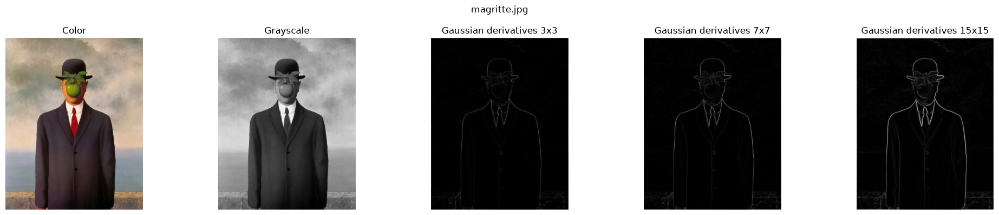

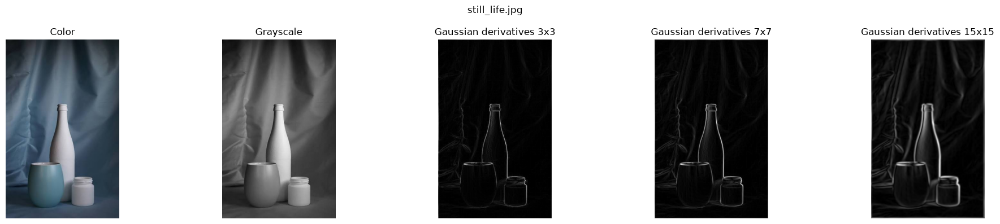

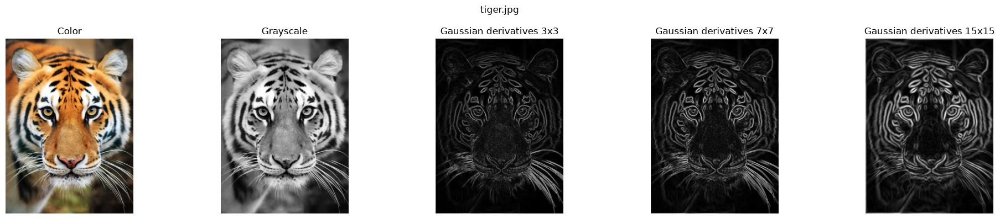

In [5]:
for name, image in images.items():
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))

    views = [
        (image, "Color", None),
        (grayscale[name], "Grayscale", "gray"),
        (edges_3[name], "Gaussian derivatives 3x3", "gray"),
        (edges_7[name], "Gaussian derivatives 7x7", "gray"),
        (edges_15[name], "Gaussian derivatives 15x15", "gray"),
    ]

    for ax, (arr, title, cmap) in zip(axes, views):
        ax.imshow(arr, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

In [6]:
from kernels import generalized_boundaries

gb_results = {}

scales = {3: 1, 7: 3, 15: 7}  # kernel size: radius

for name, image in images.items():
    gb_results[name] = {}

    for size, radius in scales.items():
        strength = generalized_boundaries(
            image,
            radius=radius,
            epsilon=1.0,
            sigma=radius / 2
        )

        gb_results[name][size] = strength

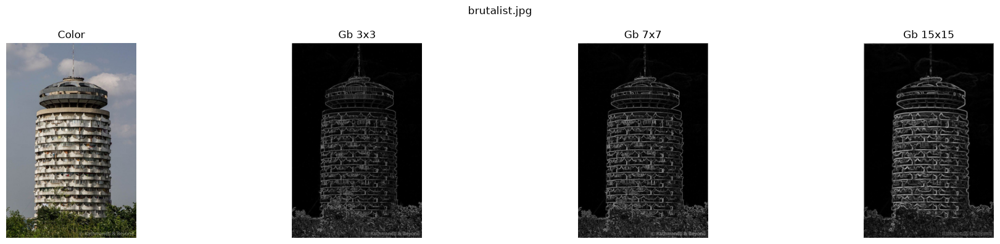

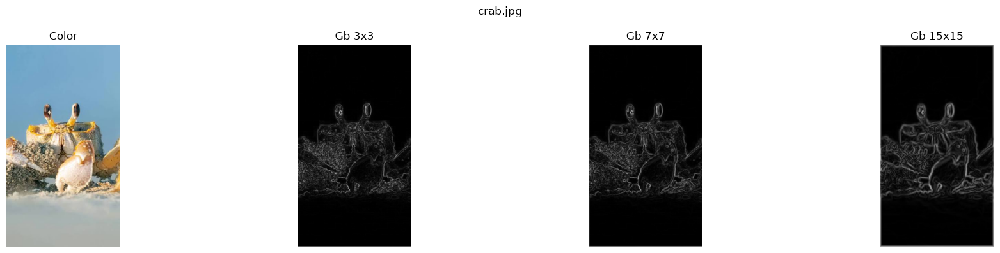

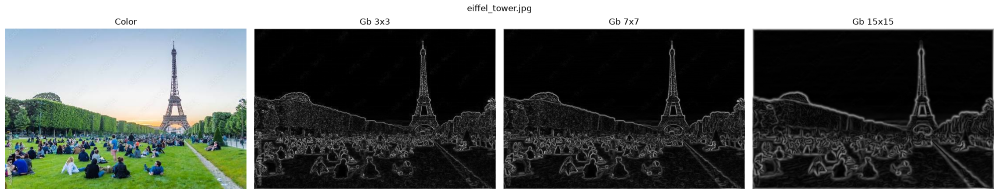

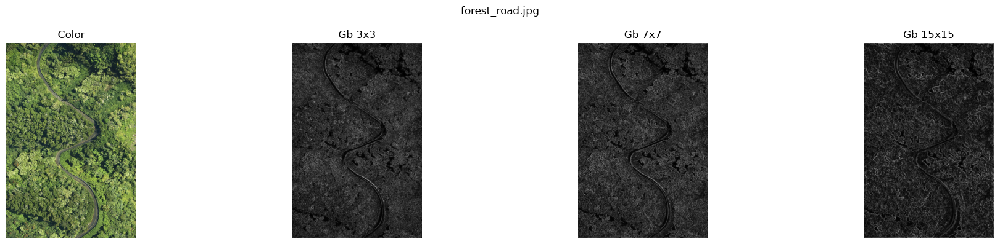

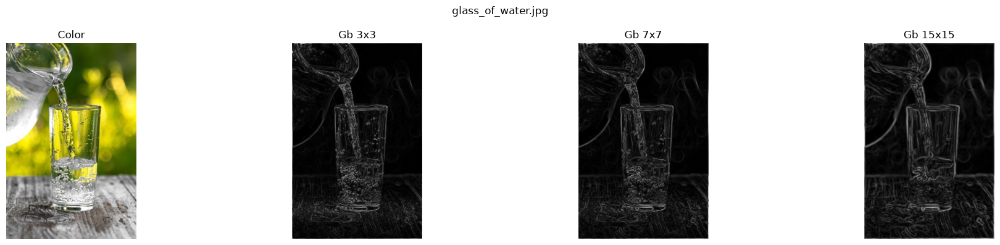

...

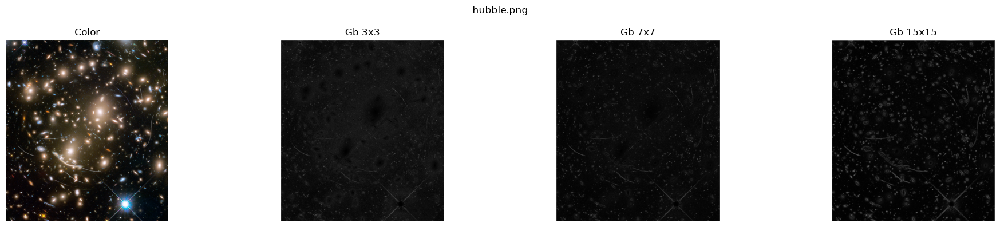

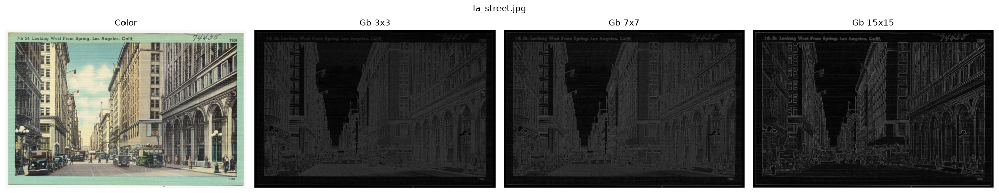

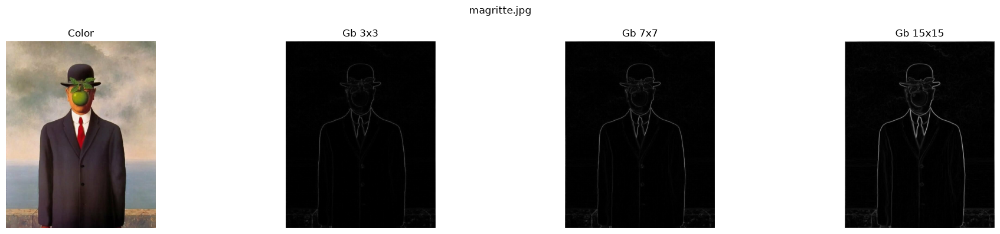

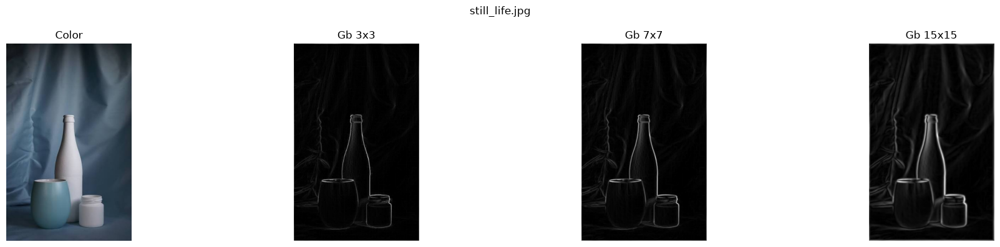

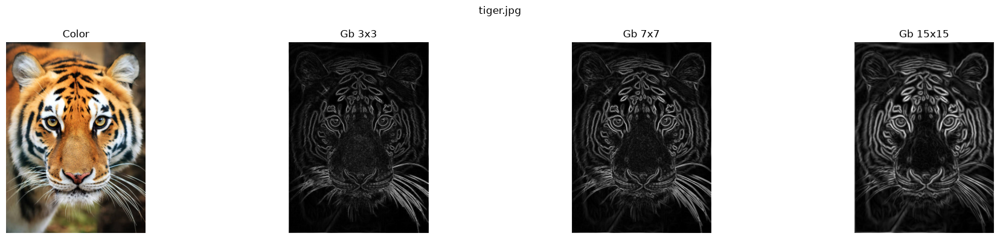

In [7]:
for name, image in images.items():
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    views = [
        (image, "Color", None),
        (gb_results[name][3], "Gb 3x3", "gray"),
        (gb_results[name][7], "Gb 7x7", "gray"),
        (gb_results[name][15], "Gb 15x15", "gray"),
    ]

    for ax, (arr, title, cmap) in zip(axes, views):
        ax.imshow(arr, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

In [8]:
gd_results = {}

scales = {3: 1, 7: 3, 15: 7}

for name, image in images.items():
    gd_results[name] = {}

    for size, radius in scales.items():
        epsilon = 100  # large enough to avoid projection

        strength = generalized_boundaries(
            image,
            radius=radius,
            epsilon=epsilon,
            sigma=radius / 2
        )

        gd_results[name][size] = strength

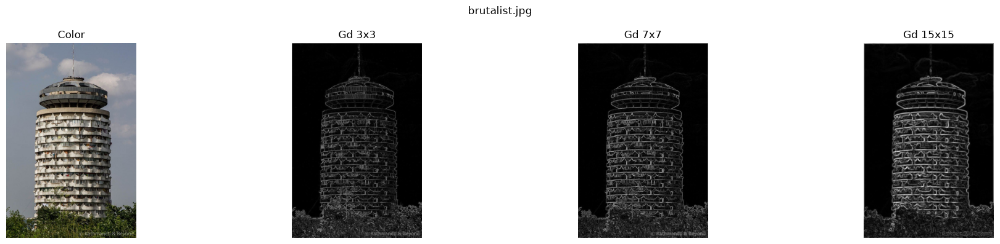

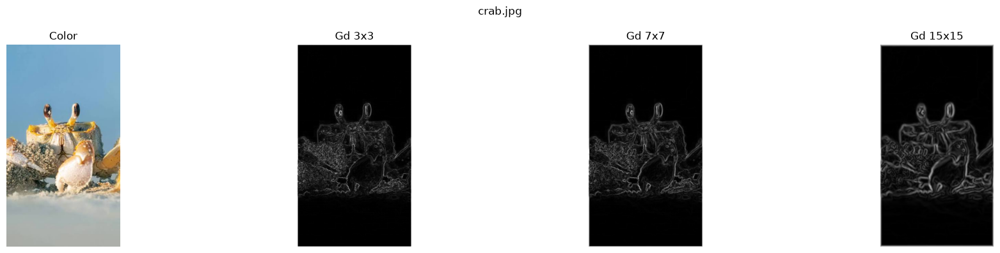

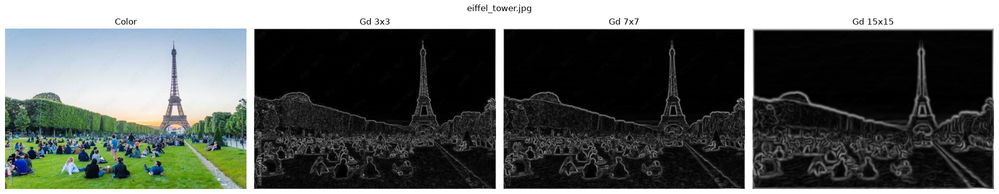

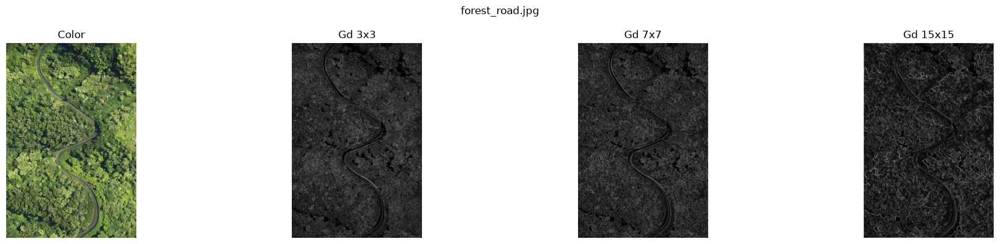

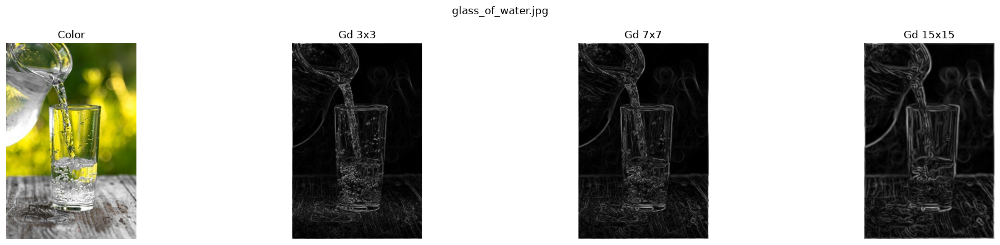

...

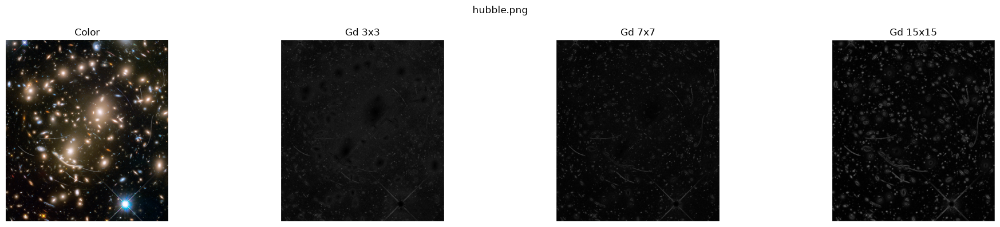

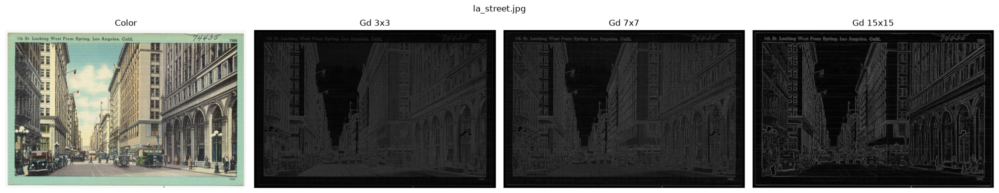

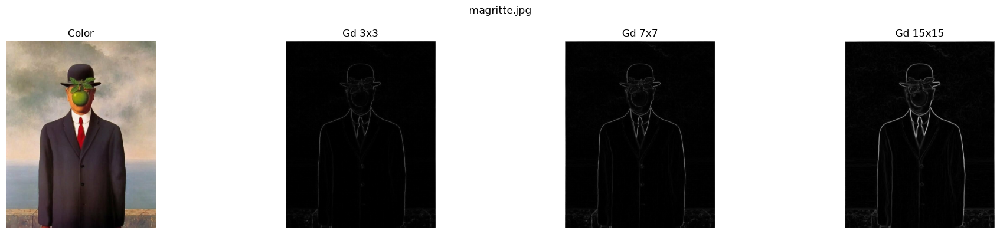

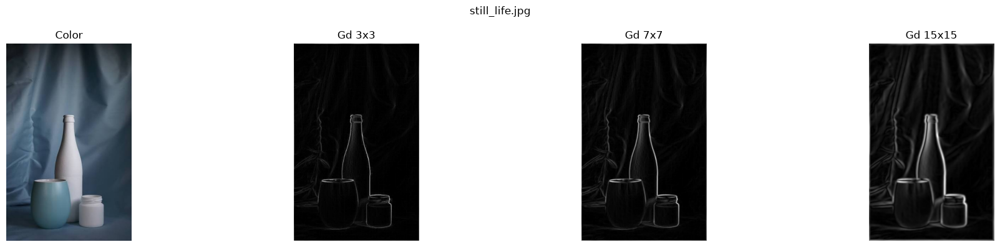

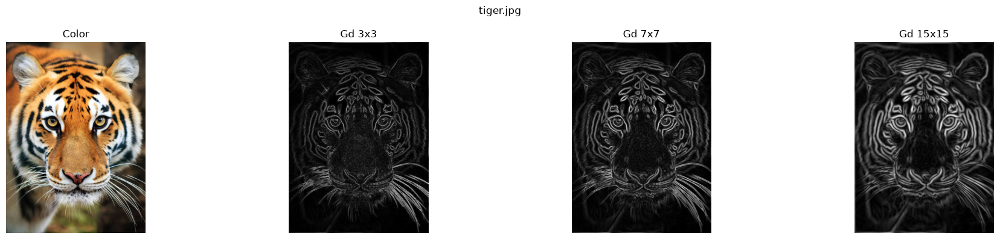

In [9]:
for name, image in images.items():
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    views = [
        (image, "Color", None),
        (gd_results[name][3], "Gd 3x3", "gray"),
        (gd_results[name][7], "Gd 7x7", "gray"),
        (gd_results[name][15], "Gd 15x15", "gray"),
    ]

    for ax, (arr, title, cmap) in zip(axes, views):
        ax.imshow(arr, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(name)
    plt.tight_layout()
    plt.show()